# 02 — Eksploracja danych (EDA)

**Cel notebooka:** zanim zbudujemy model, sprawdzić w danych, **co faktycznie wpływa na wynik**. Każde pytanie poniżej kończy się wnioskiem, który zamienimy na cechę w `03_model`.

Pytania:
1. Jak mocno pozycja startowa przesądza o wyniku?
2. Czy Singapur jest pod tym względem wyjątkowy?
3. Które zespoły się psują?
4. Kto zdobywa najszybsze okrążenie?
5. Czy porównanie z partnerem z zespołu daje sensowny ranking kierowców?
6. Czy sprint mówi coś o niedzielnym wyścigu?

## 2.0 Wczytanie danych i wspólna tabela

**Co robimy:** wczytujemy pliki z `01_dane` i budujemy jedną tabelę: dla każdego kierowcy w każdym zakończonym wyścigu — pozycja startowa (z kwalifikacji) i pozycja na mecie.

**Dlaczego:** prawie każde pytanie poniżej porównuje „start” z „metą”, więc łączymy to raz.

**Decyzja:** kierowca, który nie ukończył i nie został sklasyfikowany (`position` = NaN), dostaje pozycję **22** — ostatnią. Dla pytań „czy wygrał / był w top 10” to dokładnie prawda: nie był.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

BLUE, ORANGE, INK, MUTED = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.figsize": (9, 4), "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": "#e5e4df", "grid.linewidth": 0.8, "axes.axisbelow": True,
})

races = pd.read_csv("data/races_2026.csv")
results = pd.read_csv("data/results_2026.csv")
quali = pd.read_csv("data/quali_2026.csv")
sprint = pd.read_csv("data/sprint_2026.csv")
fastest_laps = pd.read_csv("data/fastest_laps_2026.csv")
teammate_hist = pd.read_csv("data/teammate_gaps_hist.csv")
singapore_hist = pd.read_csv("data/singapore_hist.csv")

N_DRIVERS = 22
df = (
    results[["round", "driver_number", "name_acronym", "team_name", "position", "points", "dnf", "dns"]]
    .rename(columns={"position": "finish"})
    .merge(quali[["round", "driver_number", "position"]].rename(columns={"position": "grid"}),
           on=["round", "driver_number"], how="left")
)
df["finish"] = df["finish"].fillna(N_DRIVERS)
df["grid"] = df["grid"].fillna(N_DRIVERS)
df.head()

,round,driver_number,name_acronym,team_name,finish,points,dnf,dns,grid
0,1,63,RUS,Mercedes,1.0,25.0,False,False,1.0
1,1,12,ANT,Mercedes,2.0,18.0,False,False,2.0
2,1,16,LEC,Ferrari,3.0,15.0,False,False,4.0
3,1,44,HAM,Ferrari,4.0,12.0,False,False,7.0
4,1,1,NOR,McLaren,5.0,10.0,False,False,6.0


**Co tu się dzieje:**
- `plt.rcParams.update(...)` — jednorazowe ustawienie wyglądu wszystkich wykresów: bez górnej i prawej ramki, delikatna siatka pod danymi. Dzięki temu wykresy niżej mają po 3–4 linijki.
- `rename` + `merge` — z wyników bierzemy `position` jako `finish`, z kwalifikacji `position` jako `grid`, łączymy po (`round`, `driver_number`).
- `fillna(22)` — brak pozycji = ostatni (w kwalifikacjach to np. kierowca bez czasu).

## 2.1 Jak mocno pozycja startowa przesądza o wyniku?

**Co robimy:** dla każdej pozycji startowej liczymy, jak często kierowca z niej wygrywa, staje na podium i kończy w top 10.

**Dlaczego:** jeśli pole position wygrywa np. w 60% wyścigów, to reguła „wygra pole sitter” jest naszym **baseline'em** — model ML musi ją pobić, inaczej nie ma sensu.

In [2]:
by_grid = df.groupby("grid").agg(
    starts=("finish", "size"),
    win_rate=("finish", lambda s: (s == 1).mean()),
    podium_rate=("finish", lambda s: (s <= 3).mean()),
    top10_rate=("finish", lambda s: (s <= 10).mean()),
    avg_finish=("finish", "mean"),
)
print(f"Pole position wygrywa w {by_grid.loc[1, 'win_rate']:.0%} wyścigów 2026")
by_grid.head(10).round(2)

Pole position wygrywa w 69% wyścigów 2026


,starts,win_rate,podium_rate,top10_rate,avg_finish
grid,,,,,
1.0,16,0.69,0.81,0.88,3.75
2.0,16,0.25,0.62,0.94,4.19
3.0,16,0.00,0.38,0.75,7.56
4.0,16,0.00,0.56,0.69,8.31
5.0,16,0.00,0.25,0.75,8.31
6.0,16,0.00,0.19,0.88,6.56
7.0,16,0.06,0.12,0.81,8.06
8.0,16,0.00,0.06,0.62,10.25
9.0,16,0.00,0.00,0.62,11.62


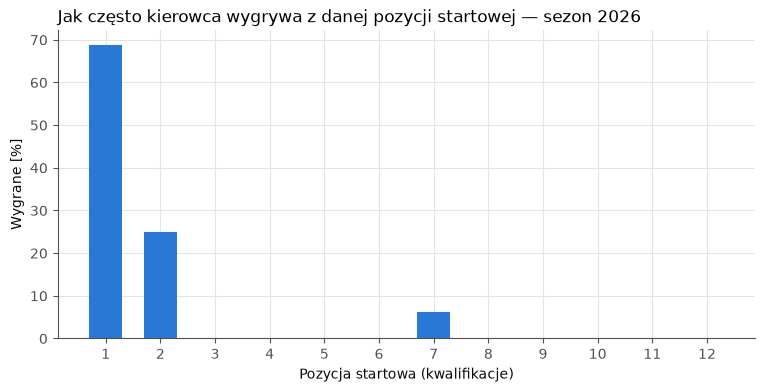

In [3]:
fig, ax = plt.subplots()
top = by_grid.loc[1:12]
ax.bar(top.index, top["win_rate"] * 100, color=BLUE, width=0.6)
ax.set_xticks(top.index)
ax.set_xlabel("Pozycja startowa (kwalifikacje)")
ax.set_ylabel("Wygrane [%]")
ax.set_title("Jak często kierowca wygrywa z danej pozycji startowej — sezon 2026", loc="left")
plt.show()

**Co tu się dzieje:**
- `groupby("grid").agg(...)` — „named aggregation”: każda nowa kolumna = (kolumna źródłowa, funkcja). `(s == 1).mean()` to udział wygranych, bo `True` liczy się jako 1.
- Wykres pokazuje tylko pozycje 1–12 — z dalszych nikt nie wygrywa.

**Wniosek:** pozycja startowa to cecha nr 1. Zapamiętaj procent wygranych z pole position — to **baseline dla zwycięzcy**.

## 2.2 Singapur: czy tu wyprzedza się jeszcze trudniej?

**Co robimy:** sprawdzamy, z jakiej pozycji wygrywano w Singapurze w latach 2023–2025 i jak bardzo zmieniały się pozycje (start → meta).

**Dlaczego:** model uczy się na średniej z całego sezonu — Monzy, gdzie wyprzedza się łatwo, i Monako, gdzie prawie wcale. Jeśli Singapur jest „bardziej startowy” niż średnia, model może **nie doceniać** pozycji startowej i warto to wiedzieć przy interpretacji.

In [4]:
sg = singapore_hist.copy()
sg["finish"] = sg["race_pos"].fillna(N_DRIVERS)
sg["grid"] = sg["quali_pos"].fillna(N_DRIVERS)

print("Zwycięzcy w Singapurze:")
print(sg[sg["finish"] == 1][["year", "name_acronym", "team_name", "grid"]].to_string(index=False))

def avg_abs_change(d):
    finished = d[d["finish"] < N_DRIVERS]
    return (finished["finish"] - finished["grid"]).abs().mean()

print(f"\nŚrednia zmiana pozycji (ukończyli): Singapur 2023–25 = {avg_abs_change(sg):.1f}, "
      f"sezon 2026 = {avg_abs_change(df):.1f}")

Zwycięzcy w Singapurze:
 year name_acronym team_name  grid
 2023          SAI   Ferrari   1.0
 2024          NOR   McLaren   1.0
 2025          RUS  Mercedes   1.0

Średnia zmiana pozycji (ukończyli): Singapur 2023–25 = 3.2, sezon 2026 = 2.8


**Co tu się dzieje:**
- `avg_abs_change` — średnia z |meta − start| dla kierowców, którzy dojechali. Im mniejsza, tym trudniej zmieniać pozycje.
- Uwaga: porównujemy inne samochody (2023–25 vs 2026), więc to wskazówka, nie dowód. Ale tor się nie zmienił — wąskie ulice zostały wąskie.

**Wniosek:** sprawdź, czy wygrywał kierowca z pole i czy zmiany pozycji w Singapurze są mniejsze niż średnio w sezonie. Jeśli tak — w Singapurze pozycja startowa waży jeszcze więcej niż w naszym modelu.

## 2.3 Niezawodność: kto się psuje?

**Co robimy:** udział startów zakończonych DNF/DNS w każdym zespole.

**Dlaczego:** w 2026 prawie co piąty start kończy się wycofaniem. Kierowca z dobrym tempem w zawodnym samochodzie częściej nie dojedzie — to powinno obniżać jego szanse na top 10.

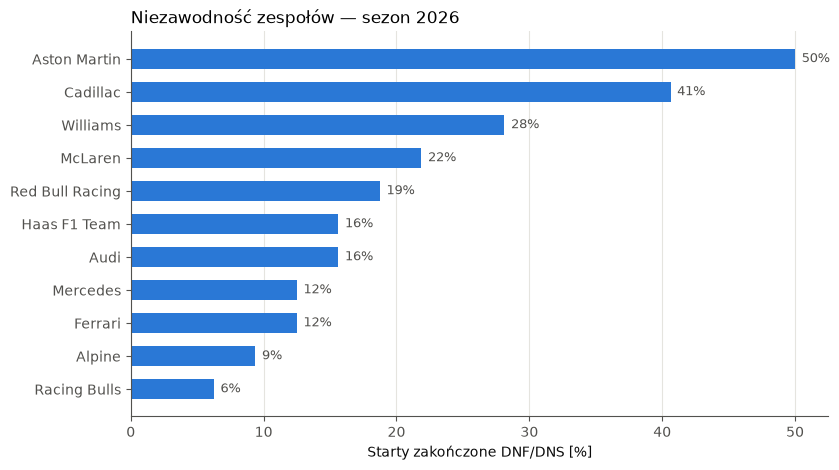

In [5]:
df["retired"] = df["dnf"] | df["dns"]
team_dnf = df.groupby("team_name")["retired"].mean().sort_values() * 100

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(team_dnf.index, team_dnf.values, color=BLUE, height=0.6)
for y, v in enumerate(team_dnf.values):
    ax.text(v + 0.5, y, f"{v:.0f}%", va="center", color=MUTED, fontsize=9)
ax.set_xlabel("Starty zakończone DNF/DNS [%]")
ax.set_title("Niezawodność zespołów — sezon 2026", loc="left")
ax.grid(axis="y", visible=False)
plt.show()

**Co tu się dzieje:**
- `dnf | dns` — „nie ukończył” albo „nie wystartował” (`|` to logiczne LUB na kolumnach).
- `barh` — poziome słupki, bo nazwy zespołów są długie. Liczby przy słupkach, żeby nie trzeba było zgadywać z osi.

**Wniosek:** różnice między zespołami są duże → cecha **`team_dnf_rate`** (liczona tylko z wyścigów *przed* danym, żeby nie podglądać przyszłości).

## 2.4 Najszybsze okrążenie: kto je zdobywa?

**Co robimy:** sprawdzamy, z jakiej pozycji startowej i na jakiej pozycji na mecie byli zdobywcy najszybszego okrążenia.

**Dlaczego:** jeśli to zwykle zwycięzca — wystarczy przewidzieć zwycięzcę. Jeśli nie — potrzebujemy osobnego modelu.

In [6]:
fl = fastest_laps.merge(df[["round", "driver_number", "grid", "finish"]], on=["round", "driver_number"], how="left")

print(f"Zwycięzca miał też najszybsze okrążenie: {(fl['finish'] == 1).mean():.0%}")
print(f"Pole sitter miał najszybsze okrążenie:   {(fl['grid'] == 1).mean():.0%}")
print(f"Zdobywca startował z top 3:              {(fl['grid'] <= 3).mean():.0%}")
fl[["round", "name_acronym", "team_name", "grid", "finish", "lap_number"]]

Zwycięzca miał też najszybsze okrążenie: 50%
Pole sitter miał najszybsze okrążenie:   38%
Zdobywca startował z top 3:              62%


,round,name_acronym,team_name,grid,finish,lap_number
0,1,VER,Red Bull Racing,22.0,6.0,42
1,2,ANT,Mercedes,1.0,1.0,52
2,3,ANT,Mercedes,1.0,1.0,49
3,4,NOR,McLaren,4.0,2.0,35
4,5,ANT,Mercedes,2.0,1.0,68
5,6,ANT,Mercedes,1.0,1.0,76
6,7,HAM,Ferrari,2.0,1.0,44
7,8,ANT,Mercedes,4.0,3.0,59
8,9,ANT,Mercedes,1.0,15.0,37
9,10,NOR,McLaren,3.0,7.0,44


**Co tu się dzieje:**
- Doklejamy do zdobywców najszybszego okrążenia ich pozycję startową i końcową.
- `lap_number` — na którym okrążeniu padł rekord. Jeśli często pod koniec wyścigu, to znak strategii (świeże opony), a nie czystego tempa.

**Wniosek:** najszybsze okrążenie jest dużo bardziej losowe niż zwycięstwo. Baseline: „zdobędzie je pole sitter”. Cechy: tempo w kwalifikacjach, siła zespołu.

## 2.5 Umiejętności kierowców (względem partnera z zespołu, 2023–2025)

**Co robimy:** dla każdego kierowcy liczymy **medianę** różnicy do partnera z zespołu w kwalifikacjach i pokazujemy tych, którzy jeżdżą w 2026.

**Dlaczego mediana, a nie średnia:** pojedyncze kwalifikacje z awarią albo wypadkiem dają różnicę rzędu kilku procent i rozjechałyby średnią. Mediana jest na to odporna.

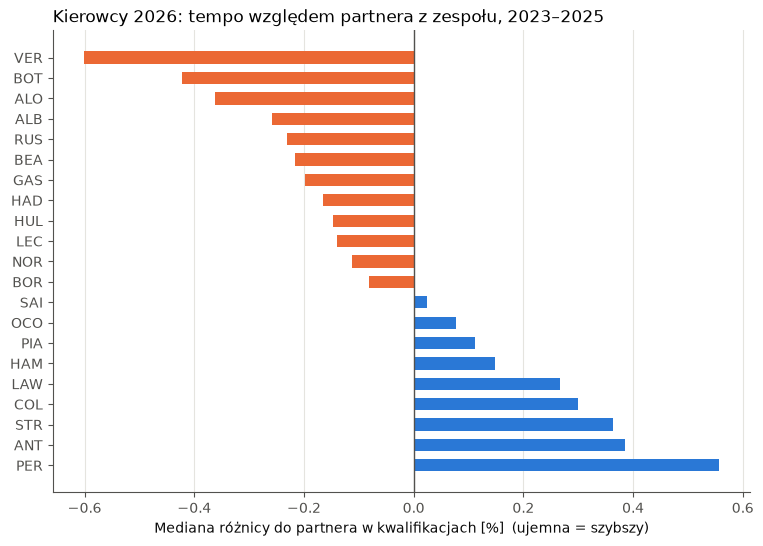

Kierowcy 2026 bez historii (debiutanci): ['LIN']


In [7]:
current = set(results.loc[results["round"] == results["round"].max(), "name_acronym"])
skill = (
    teammate_hist[teammate_hist["gap_pct"].abs() < 3]
    .groupby("name_acronym")["gap_pct"]
    .agg(median_gap="median", sessions="size")
)
skill = skill[skill.index.isin(current) & (skill["sessions"] >= 10)].sort_values("median_gap", ascending=False)

fig, ax = plt.subplots(figsize=(9, 6))
colors = [ORANGE if v < 0 else BLUE for v in skill["median_gap"]]
ax.barh(skill.index, skill["median_gap"], color=colors, height=0.6)
ax.axvline(0, color=MUTED, linewidth=1)
ax.set_xlabel("Mediana różnicy do partnera w kwalifikacjach [%]  (ujemna = szybszy)")
ax.set_title("Kierowcy 2026: tempo względem partnera z zespołu, 2023–2025", loc="left")
ax.grid(axis="y", visible=False)
plt.show()
print("Kierowcy 2026 bez historii (debiutanci):", sorted(current - set(skill.index)))

**Co tu się dzieje:**
- `abs() < 3` — wyrzucamy porównania z różnicą > 3%: to prawie na pewno awaria, wypadek albo deszcz, nie umiejętności.
- `sessions >= 10` — kierowca z 3 kwalifikacjami ma zbyt mało danych, żeby mediana coś znaczyła.
- Pomarańczowy = zwykle szybszy od partnera, niebieski = wolniejszy.

**Wniosek:** ranking powinien wyglądać sensownie (jeśli na górze są uznani mistrzowie — miara działa). To cecha **`driver_skill`**. Debiutanci jej nie mają — w `03_model` dostaną 0 („jak przeciętny partner”).

## 2.6 Czy sprint mówi coś o niedzielnym wyścigu?

**Co robimy:** w weekendach sprinterskich porównujemy wynik sprintu z wynikiem wyścigu.

**Dlaczego:** sprint to mini-wyścig na tym samym torze dzień wcześniej. Jeśli zwycięzca sprintu zwykle wygrywa w niedzielę, to cenna cecha dla Singapuru.

In [8]:
sp = (
    sprint[["round", "driver_number", "position"]].rename(columns={"position": "sprint_pos"})
    .merge(df[["round", "driver_number", "name_acronym", "grid", "finish"]], on=["round", "driver_number"])
)
print("Weekendy ze sprintem (zakończone):", sorted(sp["round"].unique()))
print(f"Zwycięzca sprintu wygrał wyścig: {(sp[sp['sprint_pos'] == 1]['finish'] == 1).mean():.0%}")
print("Korelacja (Spearman) sprint ↔ wyścig:", round(sp["sprint_pos"].corr(sp["finish"], method="spearman"), 2))
print("Korelacja (Spearman) kwalifikacje ↔ wyścig:", round(sp["grid"].corr(sp["finish"], method="spearman"), 2))

Weekendy ze sprintem (zakończone): [np.int64(2), np.int64(4), np.int64(5), np.int64(9), np.int64(12)]
Zwycięzca sprintu wygrał wyścig: 0%


Korelacja (Spearman) sprint ↔ wyścig: 0.53
Korelacja (Spearman) kwalifikacje ↔ wyścig: 0.6


**Co tu się dzieje:**
- **Korelacja Spearmana** mierzy, jak zgodne są dwie *kolejności* (1 = identyczne, 0 = brak związku). Do pozycji pasuje lepiej niż zwykła korelacja Pearsona, bo pozycje to rangi, a nie wartości liczbowe.
- Porównujemy dwie korelacje na tych samych weekendach: czy sprint przewiduje wyścig lepiej niż kwalifikacje?

**Wniosek:** mamy tylko kilka weekendów sprinterskich, więc ostrożnie. Sprint wchodzi jako cecha **`sprint_pos`**; w weekendach bez sprintu wpiszemy tam pozycję z kwalifikacji.

## 2.7 Podsumowanie: z EDA do cech

| Obserwacja | Cecha w `03_model` |
|---|---|
| Pozycja startowa dominuje (2.1, 2.2) | `grid` |
| Liczy się też, *o ile* ktoś był szybszy, nie tylko pozycja | `gap_to_pole_pct` |
| Zespoły różnią się niezawodnością (2.3) | `team_dnf_rate` (z wyścigów *przed* danym) |
| Siła samochodu w sezonie | `team_points_avg` (j.w.) |
| Forma kierowcy | `driver_form` — średnia pozycja z 3 poprzednich wyścigów |
| Umiejętności kierowcy niezależne od auta (2.5) | `driver_skill` |
| Sprint w tym samym weekendzie (2.6) | `sprint_pos` |

**Baseline'y do pobicia:** zwycięzca = pole sitter; top 3 / top 10 = pierwsze 3 / 10 pozycji startowych; najszybsze okrążenie = pole sitter.